<h1>Prashant</h1>

In [31]:
from Bio import Entrez,SeqIO,Seq
from Bio.SeqUtils import GC123
from collections import Counter
import pandas as pd
Species={
    'Homo_sapiens':"NC_012920",
    'Mus_musculus':'NC_005089',
    'Danio_rerio':'NC_002333'
}

#print(species)

In [54]:

Entrez.email='sainiprashant712@gmail.com'
Dataset=[]
target_genes=['COX1', 'ND1', 'CYTB', 'ATP6', 'RNR1','mt-Rnr1','mt-rnr1']
for species,accessions in Species.items():
    handle=Entrez.efetch(db='nucleotide',id=accessions,rettype='gb',retmode='text')
    record=SeqIO.read(handle,'genbank')
    handle.close()
    #print(record)
    #print(record.seq)
    #print(record.features)
    #print(record.description)
    for rec in record.features:
        #print(rec)
        #print(rec.id)
        #print(rec.qualifiers)
        #print(rec.type)
        gene_name=rec.qualifiers.get('gene',[''])[0]
        #print(gene_name,type(gene_name))
        if gene_name in target_genes:
            #print(gene_name)
            gene_sequence=rec.extract(record.seq)            
            #print(species,gene_name,gene_sequence,gene_sequence.transcribe())
            count_from_dna=dict(Counter(gene_sequence))
            #print(count_from_dns)
            Dataset.append({
                'species':species,
                'Gene':gene_name,
                'Gene Sequence':gene_sequence,
                'GC':GC123(gene_sequence)[0],
                "Length":len(gene_sequence),
                "A":count_from_dna['A'],
                'T':count_from_dna['T'],
                'G':count_from_dna['G'],
                'C':count_from_dna['C'],
                'RNA':gene_sequence.transcribe(),
                'protien':gene_sequence.translate(),
                })
Dataset

[{'species': 'Homo_sapiens',
  'Gene': 'RNR1',
  'Gene Sequence': Seq('AATAGGTTTGGTCCTAGCCTTTCTATTAGCTCTTAGTAAGATTACACATGCAAG...AAC'),
  'GC': 45.492662473794546,
  'Length': 954,
  'A': 315,
  'T': 205,
  'G': 181,
  'C': 253,
  'RNA': Seq('AAUAGGUUUGGUCCUAGCCUUUCUAUUAGCUCUUAGUAAGAUUACACAUGCAAG...AAC'),
  'protien': Seq('NRFGPSLSISS**DYTCKHPRSSEFTL*ITTIKRNKHQARSNAAQNA*PSHTPT...WTN')},
 {'species': 'Homo_sapiens',
  'Gene': 'RNR1',
  'Gene Sequence': Seq('AATAGGTTTGGTCCTAGCCTTTCTATTAGCTCTTAGTAAGATTACACATGCAAG...AAC'),
  'GC': 45.492662473794546,
  'Length': 954,
  'A': 315,
  'T': 205,
  'G': 181,
  'C': 253,
  'RNA': Seq('AAUAGGUUUGGUCCUAGCCUUUCUAUUAGCUCUUAGUAAGAUUACACAUGCAAG...AAC'),
  'protien': Seq('NRFGPSLSISS**DYTCKHPRSSEFTL*ITTIKRNKHQARSNAAQNA*PSHTPT...WTN')},
 {'species': 'Homo_sapiens',
  'Gene': 'ND1',
  'Gene Sequence': Seq('ATACCCATGGCCAACCTCCTACTCCTCATTGTACCCATTCTAATCGCAATGGCA...CTA'),
  'GC': 47.69874476987448,
  'Length': 956,
  'A': 272,
  'T': 228,
  'G': 112,
  'C': 3

In [35]:
df=pd.DataFrame(Dataset)
df

,species,Gene,Gene Sequence,GC,Length,A,T,G,C,RNA,protien
0,Homo_sapiens,RNR1,"(A, A, T, A, G, G, T, T, T, G, G, T, C, C, T, ...",45.492662,954,315,205,181,253,"(A, A, U, A, G, G, U, U, U, G, G, U, C, C, U, ...","(N, R, F, G, P, S, L, S, I, S, S, *, *, D, Y, ..."
1,Homo_sapiens,RNR1,"(A, A, T, A, G, G, T, T, T, G, G, T, C, C, T, ...",45.492662,954,315,205,181,253,"(A, A, U, A, G, G, U, U, U, G, G, U, C, C, U, ...","(N, R, F, G, P, S, L, S, I, S, S, *, *, D, Y, ..."
2,Homo_sapiens,ND1,"(A, T, A, C, C, C, A, T, G, G, C, C, A, A, C, ...",47.698745,956,272,228,112,344,"(A, U, A, C, C, C, A, U, G, G, C, C, A, A, C, ...","(I, P, M, A, N, L, L, L, L, I, V, P, I, L, I, ..."
3,Homo_sapiens,ND1,"(A, T, A, C, C, C, A, T, G, G, C, C, A, A, C, ...",47.698745,956,272,228,112,344,"(A, U, A, C, C, C, A, U, G, G, C, C, A, A, C, ...","(I, P, M, A, N, L, L, L, L, I, V, P, I, L, I, ..."
4,Homo_sapiens,COX1,"(A, T, G, T, T, C, G, C, C, G, A, C, C, G, T, ...",46.238651,1542,419,410,250,463,"(A, U, G, U, U, C, G, C, C, G, A, C, C, G, U, ...","(M, F, A, D, R, *, L, F, S, T, N, H, K, D, I, ..."
5,Homo_sapiens,COX1,"(A, T, G, T, T, C, G, C, C, G, A, C, C, G, T, ...",46.238651,1542,419,410,250,463,"(A, U, G, U, U, C, G, C, C, G, A, C, C, G, U, ...","(M, F, A, D, R, *, L, F, S, T, N, H, K, D, I, ..."
6,Homo_sapiens,ATP6,"(A, T, G, A, A, C, G, A, A, A, A, T, C, T, G, ...",44.199706,681,206,174,71,230,"(A, U, G, A, A, C, G, A, A, A, A, U, C, U, G, ...","(M, N, E, N, L, F, A, S, F, I, A, P, T, I, L, ..."
7,Homo_sapiens,ATP6,"(A, T, G, A, A, C, G, A, A, A, A, T, C, T, G, ...",44.199706,681,206,174,71,230,"(A, U, G, A, A, C, G, A, A, A, A, U, C, U, G, ...","(M, N, E, N, L, F, A, S, F, I, A, P, T, I, L, ..."
8,Homo_sapiens,CYTB,"(A, T, G, A, C, C, C, C, A, A, T, A, C, G, C, ...",46.275197,1141,326,287,137,391,"(A, U, G, A, C, C, C, C, A, A, U, A, C, G, C, ...","(M, T, P, I, R, K, T, N, P, L, I, K, L, I, N, ..."
9,Homo_sapiens,CYTB,"(A, T, G, A, C, C, C, C, A, A, T, A, C, G, C, ...",46.275197,1141,326,287,137,391,"(A, U, G, A, C, C, C, C, A, A, U, A, C, G, C, ...","(M, T, P, I, R, K, T, N, P, L, I, K, L, I, N, ..."


In [36]:
for index,gene in enumerate(df['Gene']):
    if gene in ['mt-Rnr1','mt-rnr1']:
        df.loc[index,'Gene']='RNR1'

In [37]:
df

,species,Gene,Gene Sequence,GC,Length,A,T,G,C,RNA,protien
0,Homo_sapiens,RNR1,"(A, A, T, A, G, G, T, T, T, G, G, T, C, C, T, ...",45.492662,954,315,205,181,253,"(A, A, U, A, G, G, U, U, U, G, G, U, C, C, U, ...","(N, R, F, G, P, S, L, S, I, S, S, *, *, D, Y, ..."
1,Homo_sapiens,RNR1,"(A, A, T, A, G, G, T, T, T, G, G, T, C, C, T, ...",45.492662,954,315,205,181,253,"(A, A, U, A, G, G, U, U, U, G, G, U, C, C, U, ...","(N, R, F, G, P, S, L, S, I, S, S, *, *, D, Y, ..."
2,Homo_sapiens,ND1,"(A, T, A, C, C, C, A, T, G, G, C, C, A, A, C, ...",47.698745,956,272,228,112,344,"(A, U, A, C, C, C, A, U, G, G, C, C, A, A, C, ...","(I, P, M, A, N, L, L, L, L, I, V, P, I, L, I, ..."
3,Homo_sapiens,ND1,"(A, T, A, C, C, C, A, T, G, G, C, C, A, A, C, ...",47.698745,956,272,228,112,344,"(A, U, A, C, C, C, A, U, G, G, C, C, A, A, C, ...","(I, P, M, A, N, L, L, L, L, I, V, P, I, L, I, ..."
4,Homo_sapiens,COX1,"(A, T, G, T, T, C, G, C, C, G, A, C, C, G, T, ...",46.238651,1542,419,410,250,463,"(A, U, G, U, U, C, G, C, C, G, A, C, C, G, U, ...","(M, F, A, D, R, *, L, F, S, T, N, H, K, D, I, ..."
5,Homo_sapiens,COX1,"(A, T, G, T, T, C, G, C, C, G, A, C, C, G, T, ...",46.238651,1542,419,410,250,463,"(A, U, G, U, U, C, G, C, C, G, A, C, C, G, U, ...","(M, F, A, D, R, *, L, F, S, T, N, H, K, D, I, ..."
6,Homo_sapiens,ATP6,"(A, T, G, A, A, C, G, A, A, A, A, T, C, T, G, ...",44.199706,681,206,174,71,230,"(A, U, G, A, A, C, G, A, A, A, A, U, C, U, G, ...","(M, N, E, N, L, F, A, S, F, I, A, P, T, I, L, ..."
7,Homo_sapiens,ATP6,"(A, T, G, A, A, C, G, A, A, A, A, T, C, T, G, ...",44.199706,681,206,174,71,230,"(A, U, G, A, A, C, G, A, A, A, A, U, C, U, G, ...","(M, N, E, N, L, F, A, S, F, I, A, P, T, I, L, ..."
8,Homo_sapiens,CYTB,"(A, T, G, A, C, C, C, C, A, A, T, A, C, G, C, ...",46.275197,1141,326,287,137,391,"(A, U, G, A, C, C, C, C, A, A, U, A, C, G, C, ...","(M, T, P, I, R, K, T, N, P, L, I, K, L, I, N, ..."
9,Homo_sapiens,CYTB,"(A, T, G, A, C, C, C, C, A, A, T, A, C, G, C, ...",46.275197,1141,326,287,137,391,"(A, U, G, A, C, C, C, C, A, A, U, A, C, G, C, ...","(M, T, P, I, R, K, T, N, P, L, I, K, L, I, N, ..."


In [ ]:

df.drop_duplicates(inplace=True)
df.to_csv('mtDNA_genes(1).csv',index=False)


        

In [ ]:
df=pd.read_csv('mtDNA_genes(1).csv')
df

,species,Gene,Gene Sequence,GC,Length,A,T,G,C,RNA,protien
0,Homo_sapiens,RNR1,AATAGGTTTGGTCCTAGCCTTTCTATTAGCTCTTAGTAAGATTACA...,45.492662,954,315,205,181,253,AAUAGGUUUGGUCCUAGCCUUUCUAUUAGCUCUUAGUAAGAUUACA...,NRFGPSLSISS**DYTCKHPRSSEFTL*ITTIKRNKHQARSNAAQN...
1,Homo_sapiens,ND1,ATACCCATGGCCAACCTCCTACTCCTCATTGTACCCATTCTAATCG...,47.698745,956,272,228,112,344,AUACCCAUGGCCAACCUCCUACUCCUCAUUGUACCCAUUCUAAUCG...,IPMANLLLLIVPILIAMAFLMLTERKILGYIQLRKGPNVVGPYGLL...
2,Homo_sapiens,COX1,ATGTTCGCCGACCGTTGACTATTCTCTACAAACCACAAAGACATTG...,46.238651,1542,419,410,250,463,AUGUUCGCCGACCGUUGACUAUUCUCUACAAACCACAAAGACAUUG...,MFADR*LFSTNHKDIGTLYLLFGA*AGVLGTALSLLIRAELGQPGN...
3,Homo_sapiens,ATP6,ATGAACGAAAATCTGTTCGCTTCATTCATTGCCCCCACAATCCTAG...,44.199706,681,206,174,71,230,AUGAACGAAAAUCUGUUCGCUUCAUUCAUUGCCCCCACAAUCCUAG...,MNENLFASFIAPTILGLPAAVLIILFPPLLIPTSKYLINNRLITTQ...
4,Homo_sapiens,CYTB,ATGACCCCAATACGCAAAACTAACCCCCTAATAAAATTAATTAACC...,46.275197,1141,326,287,137,391,AUGACCCCAAUACGCAAAACUAACCCCCUAAUAAAAUUAAUUAACC...,MTPIRKTNPLIKLINHSFIDLPTPSNISA**NFGSLLGACLILQIT...
5,Mus_musculus,RNR1,AAAGGTTTGGTCCTGGCCTTATAATTAATTAGAGGTAAAATTACAC...,35.811518,955,361,252,154,188,AAAGGUUUGGUCCUGGCCUUAUAAUUAAUUAGAGGUAAAAUUACAC...,KGLVLAL*LIRGKITHANLHRPV*NPLNIYLKFKERVSSTLK*LKT...
6,Mus_musculus,ND1,GTGTTCTTTATTAATATCCTAACACTCCTCGTCCCCATTCTAATCG...,37.617555,957,309,288,111,249,GUGUUCUUUAUUAAUAUCCUAACACUCCUCGUCCCCAUUCUAAUCG...,VFFINILTLLVPILIAIAFLTLVERKILGYIQLRKGPNIVGPYGIL...
7,Mus_musculus,COX1,ATGTTCATTAATCGTTGATTATTCTCAACCAATCACAAAGATATCG...,39.870550,1545,456,473,249,367,AUGUUCAUUAAUCGUUGAUUAUUCUCAACCAAUCACAAAGAUAUCG...,MFINR*LFSTNHKDIGTLYLLFGA*AGIVGTALSILIRAELGQPGA...
8,Mus_musculus,ATP6,ATGAACGAAAATCTATTTGCCTCATTCATTACCCCAACAATAATAG...,35.976505,681,232,204,66,179,AUGAACGAAAAUCUAUUUGCCUCAUUCAUUACCCCAACAAUAAUAG...,MNENLFASFITPTIIGFPIVVAIIIFPSILFPSSKRLINNRLHSFQ...
9,Mus_musculus,CYTB,ATGACAAACATACGAAAAACACACCCATTATTTAAAATTATTAACC...,39.073427,1144,363,334,139,308,AUGACAAACAUACGAAAAACACACCCAUUAUUUAAAAUUAUUAACC...,MTNIRKTHPLFKIINHSFIDLPAPSNISS**NFGSLLGVCLIVQII...


In [ ]:
import seaborn as sns 
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
homo_sapiens=df.loc[df['species']=='Homo_sapiens',:].reset_index()


In [ ]:
'''target_genes=['COX1', 'ND1', 'CYTB', 'ATP6', 'RNR1']

def Five_Pie_chart(Specie,target_genes):
    fig, axes=plt.subplots(nrows=5,ncols=1,figsize=(15,15),dpi=200)
    for k,j in enumerate(target_genes):
        #print(k,j)
        species_=df.loc[df['species']==Specie,:]
        #print(species_)
        data=species_.loc[species_['Gene']==j,:].reset_index(drop=True).loc[0]
        axes[k].pie(list(data[['A','T','G','C']]),labels=['A','T','G','C'],autopct='%0.2f%%',)
        axes[k].set_title(f"Adenine (A), Thymine (T), Cytosine (C), and Guanine (G) present in {j}-{Specie}")

for i in Species.keys():
    print(f"The Graph For {i} genes")
    Five_Pie_chart(i,target_genes=target_genes)'''



'target_genes=[\'COX1\', \'ND1\', \'CYTB\', \'ATP6\', \'RNR1\']\n\ndef Five_Pie_chart(Specie,target_genes):\n    fig, axes=plt.subplots(nrows=5,ncols=1,figsize=(15,15),dpi=200)\n    for k,j in enumerate(target_genes):\n        #print(k,j)\n        species_=df.loc[df[\'species\']==Specie,:]\n        #print(species_)\n        data=species_.loc[species_[\'Gene\']==j,:].reset_index(drop=True).loc[0]\n        axes[k].pie(list(data[[\'A\',\'T\',\'G\',\'C\']]),labels=[\'A\',\'T\',\'G\',\'C\'],autopct=\'%0.2f%%\',)\n        axes[k].set_title(f"Adenine (A), Thymine (T), Cytosine (C), and Guanine (G) present in {j}-{Specie}")\n\nfor i in Species.keys():\n    print(f"The Graph For {i} genes")\n    Five_Pie_chart(i,target_genes=target_genes)'

Text(0.5, 1.0, 'Adenine (A), Thymine (T), Cytosine (C), and \nGuanine (G) present in of human RNR1')

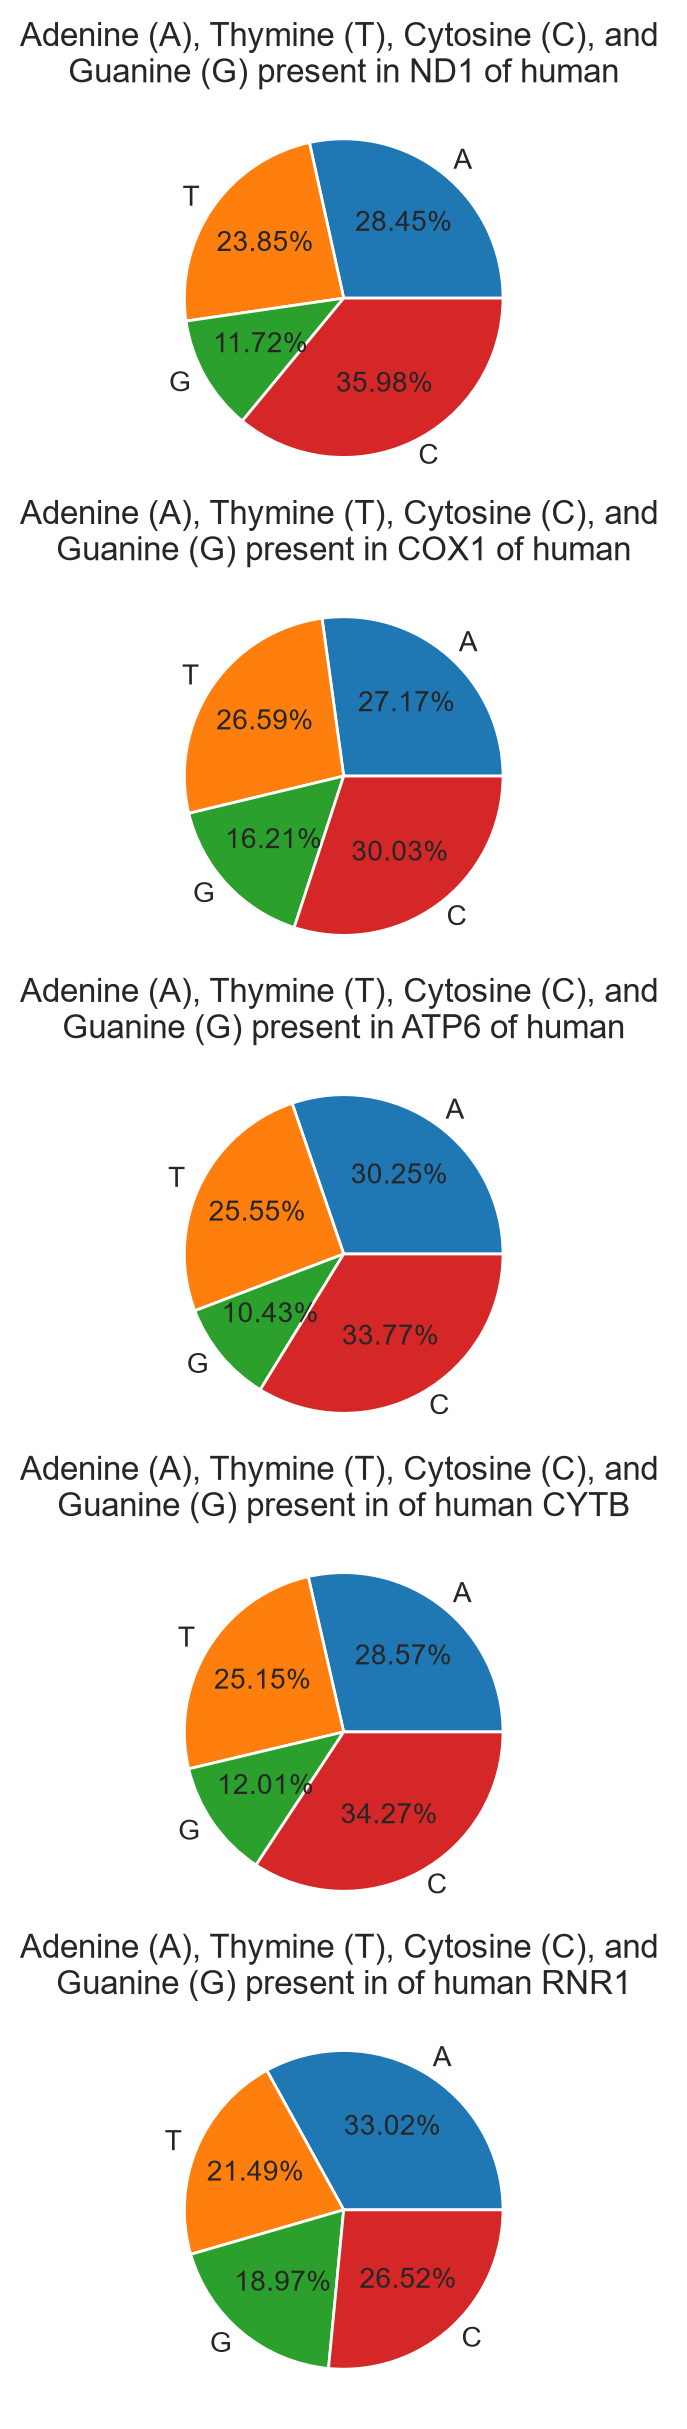

In [ ]:
fig, axes=plt.subplots(nrows=5,ncols=1,figsize=(10,15),dpi=200)
homo_sapiens=df.loc[df['species']=='Homo_sapiens',:].reset_index()
# ND1
data=homo_sapiens.loc[homo_sapiens['Gene']=='ND1',:].loc[1]
axes[0].pie(list(data[['A','T','G','C']]),labels=['A','T','G','C'],autopct='%0.2f%%',)
axes[0].set_title("Adenine (A), Thymine (T), Cytosine (C), and \nGuanine (G) present in ND1 of human")
#homo_sapiens=df.loc[df['species']=='Homo_sapiens',:]
# COX1
data=homo_sapiens.loc[homo_sapiens['Gene']=='COX1',:]
data=data.loc[:].loc[2]
axes[1].pie(list(data[['A','T','G','C']]),labels=['A','T','G','C'],autopct='%0.2f%%')
axes[1].set_title("Adenine (A), Thymine (T), Cytosine (C), and \nGuanine (G) present in COX1 of human")
#homo_sapiens=df.loc[df['species']=='Homo_sapiens',:]
# ATP6
data=homo_sapiens.loc[homo_sapiens['Gene']=='ATP6',:]
data=data.loc[:].loc[3]
#data
axes[2].pie(list(data[['A','T','G','C']]),labels=['A','T','G','C'],autopct='%0.2f%%')
axes[2].set_title("Adenine (A), Thymine (T), Cytosine (C), and \nGuanine (G) present in ATP6 of human")
data=homo_sapiens.loc[homo_sapiens['Gene']=='CYTB',:]
data=data.loc[:].loc[4]
#print(data)
#CYTB
axes[3].pie(list(data[['A','T','G','C']]),labels=['A','T','G','C'],autopct='%0.2f%%')
axes[3].set_title("Adenine (A), Thymine (T), Cytosine (C), and \nGuanine (G) present in of human CYTB")

data=homo_sapiens.loc[homo_sapiens['Gene']=='RNR1',:]
data=data.loc[:].loc[0]
#print(data)
#CYTB
axes[4].pie(list(data[['A','T','G','C']]),labels=['A','T','G','C'],autopct='%0.2f%%')
axes[4].set_title("Adenine (A), Thymine (T), Cytosine (C), and \nGuanine (G) present in of human RNR1")



<h1>Prashant</h1>

Text(0.5, 1.0, 'Adenine (A), Thymine (T), Cytosine (C), and \nGuanine (G) present in of Mouse RNR1')

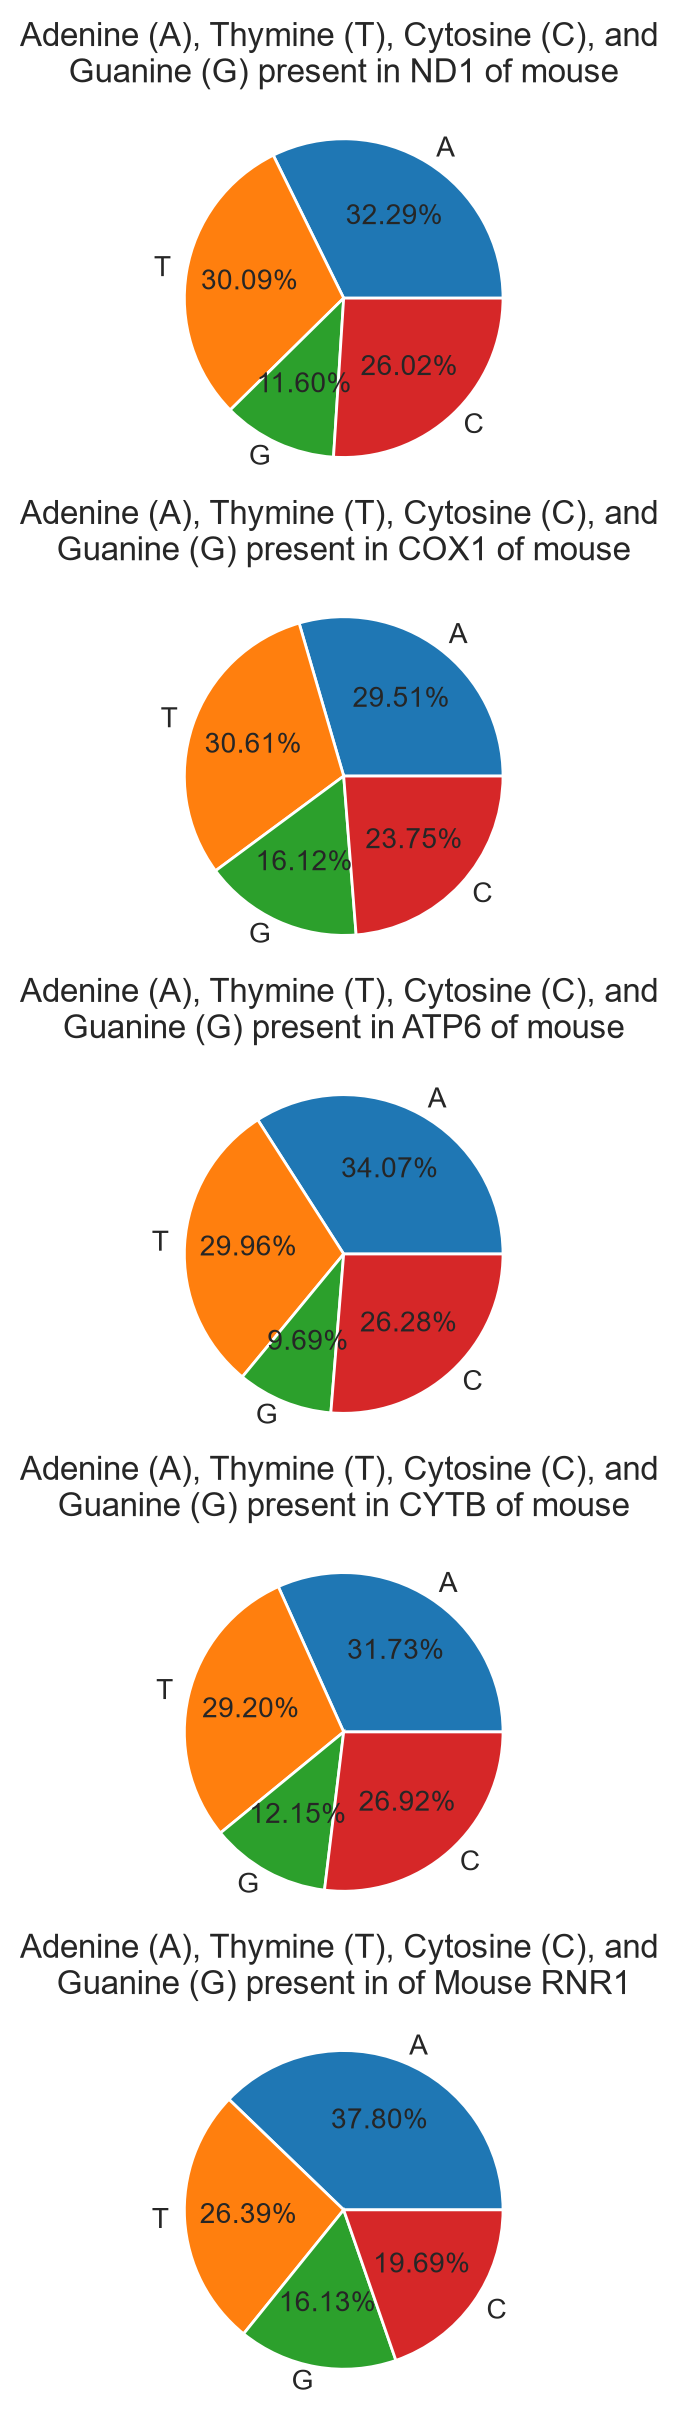

In [ ]:
fig, axes=plt.subplots(nrows=5,ncols=1,figsize=(20,15),dpi=200)
species_=df.loc[df['species']=='Mus_musculus',:].reset_index()
# ND1
data=species_.loc[species_['Gene']=='ND1',:].loc[1]
axes[0].pie(list(data[['A','T','G','C']]),labels=['A','T','G','C'],autopct='%0.2f%%')
axes[0].set_title("Adenine (A), Thymine (T), Cytosine (C), and \nGuanine (G) present in ND1 of mouse")
# COX1
data=species_.loc[species_['Gene']=='COX1',:]
data=data.loc[:].loc[2]
axes[1].pie(list(data[['A','T','G','C']]),labels=['A','T','G','C'],autopct='%0.2f%%')
axes[1].set_title("Adenine (A), Thymine (T), Cytosine (C), and \nGuanine (G) present in COX1 of mouse")
# ATP6
data=species_.loc[species_['Gene']=='ATP6',:]
data=data.loc[:].loc[3]
#data
axes[2].pie(list(data[['A','T','G','C']]),labels=['A','T','G','C'],autopct='%0.2f%%')
axes[2].set_title("Adenine (A), Thymine (T), Cytosine (C), and \nGuanine (G) present in ATP6 of mouse")

data=species_.loc[species_['Gene']=='CYTB',:]
data=data.loc[:].loc[4]
#print(data)
#CYTB
axes[3].pie(list(data[['A','T','G','C']]),labels=['A','T','G','C'],autopct='%0.2f%%')
axes[3].set_title("Adenine (A), Thymine (T), Cytosine (C), and \nGuanine (G) present in CYTB of mouse")



data=species_.loc[species_['Gene']=='RNR1',:]
data=data.loc[:].loc[0]
#print(data)
#mt-Rnr1
axes[4].pie(list(data[['A','T','G','C']]),labels=['A','T','G','C'],autopct='%0.2f%%')
axes[4].set_title("Adenine (A), Thymine (T), Cytosine (C), and \nGuanine (G) present in of Mouse RNR1")



Text(0.5, 1.0, 'Adenine (A), Thymine (T), Cytosine (C), and \nGuanine (G) present in of zebrafish RNR1')

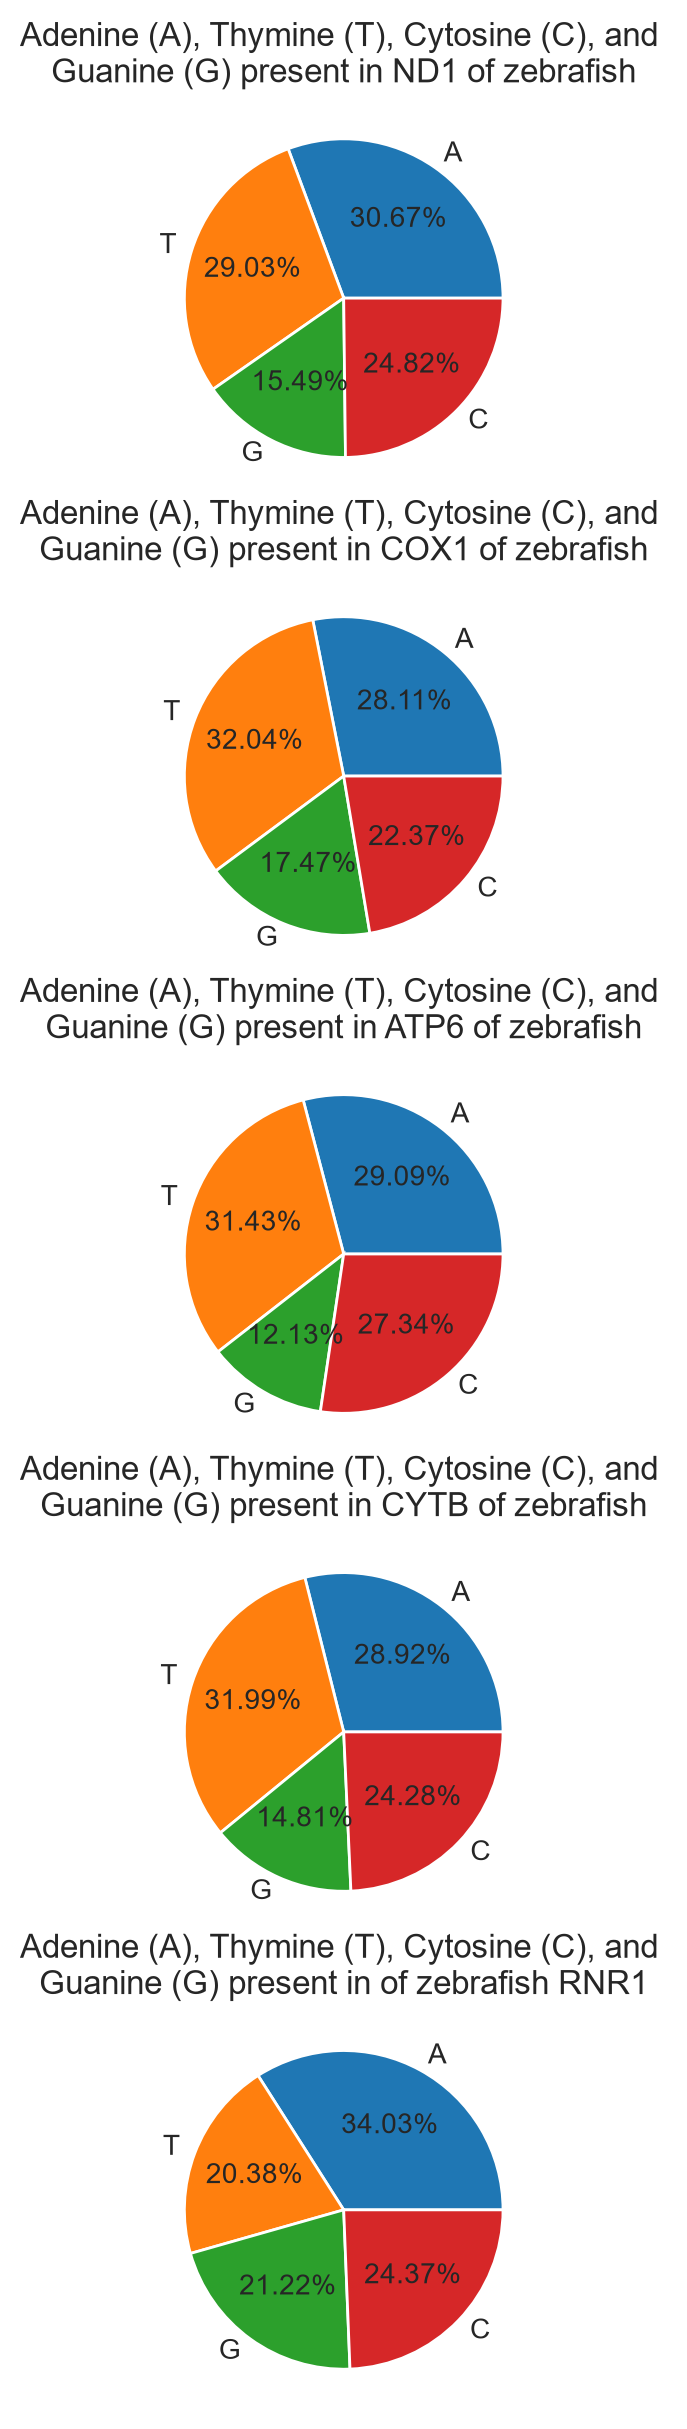

In [ ]:
fig, axes=plt.subplots(nrows=5,ncols=1,figsize=(20,15),dpi=200)
species_=df.loc[df['species']=='Danio_rerio',:].reset_index()
# ND1
data=species_.loc[species_['Gene']=='ND1',:].loc[1]
axes[0].pie(list(data[['A','T','G','C']]),labels=['A','T','G','C'],autopct='%0.2f%%')
axes[0].set_title("Adenine (A), Thymine (T), Cytosine (C), and \nGuanine (G) present in ND1 of zebrafish")
#homo_sapiens=df.loc[df['species']=='Homo_sapiens',:]
# COX1
data=species_.loc[species_['Gene']=='COX1',:]
data=data.loc[:].loc[2]
axes[1].pie(list(data[['A','T','G','C']]),labels=['A','T','G','C'],autopct='%0.2f%%')
axes[1].set_title("Adenine (A), Thymine (T), Cytosine (C), and \nGuanine (G) present in COX1 of zebrafish")
#homo_sapiens=df.loc[df['species']=='Homo_sapiens',:]
# ATP6
data=species_.loc[species_['Gene']=='ATP6',:]
data=data.loc[:].loc[3]
#data
axes[2].pie(list(data[['A','T','G','C']]),labels=['A','T','G','C'],autopct='%0.2f%%')
axes[2].set_title("Adenine (A), Thymine (T), Cytosine (C), and \nGuanine (G) present in ATP6 of zebrafish")
data=species_.loc[species_['Gene']=='CYTB',:]
data=data.loc[:].loc[4]
#print(data)
#CYTB
axes[3].pie(list(data[['A','T','G','C']]),labels=['A','T','G','C'],autopct='%0.2f%%')
axes[3].set_title("Adenine (A), Thymine (T), Cytosine (C), and \nGuanine (G) present in CYTB of zebrafish")
data=species_.loc[species_['Gene']=='RNR1',:]
data=data.loc[:].loc[0]
#print(data)
#mt-Rnr1
axes[4].pie(list(data[['A','T','G','C']]),labels=['A','T','G','C'],autopct='%0.2f%%')
axes[4].set_title("Adenine (A), Thymine (T), Cytosine (C), and \nGuanine (G) present in of zebrafish RNR1")


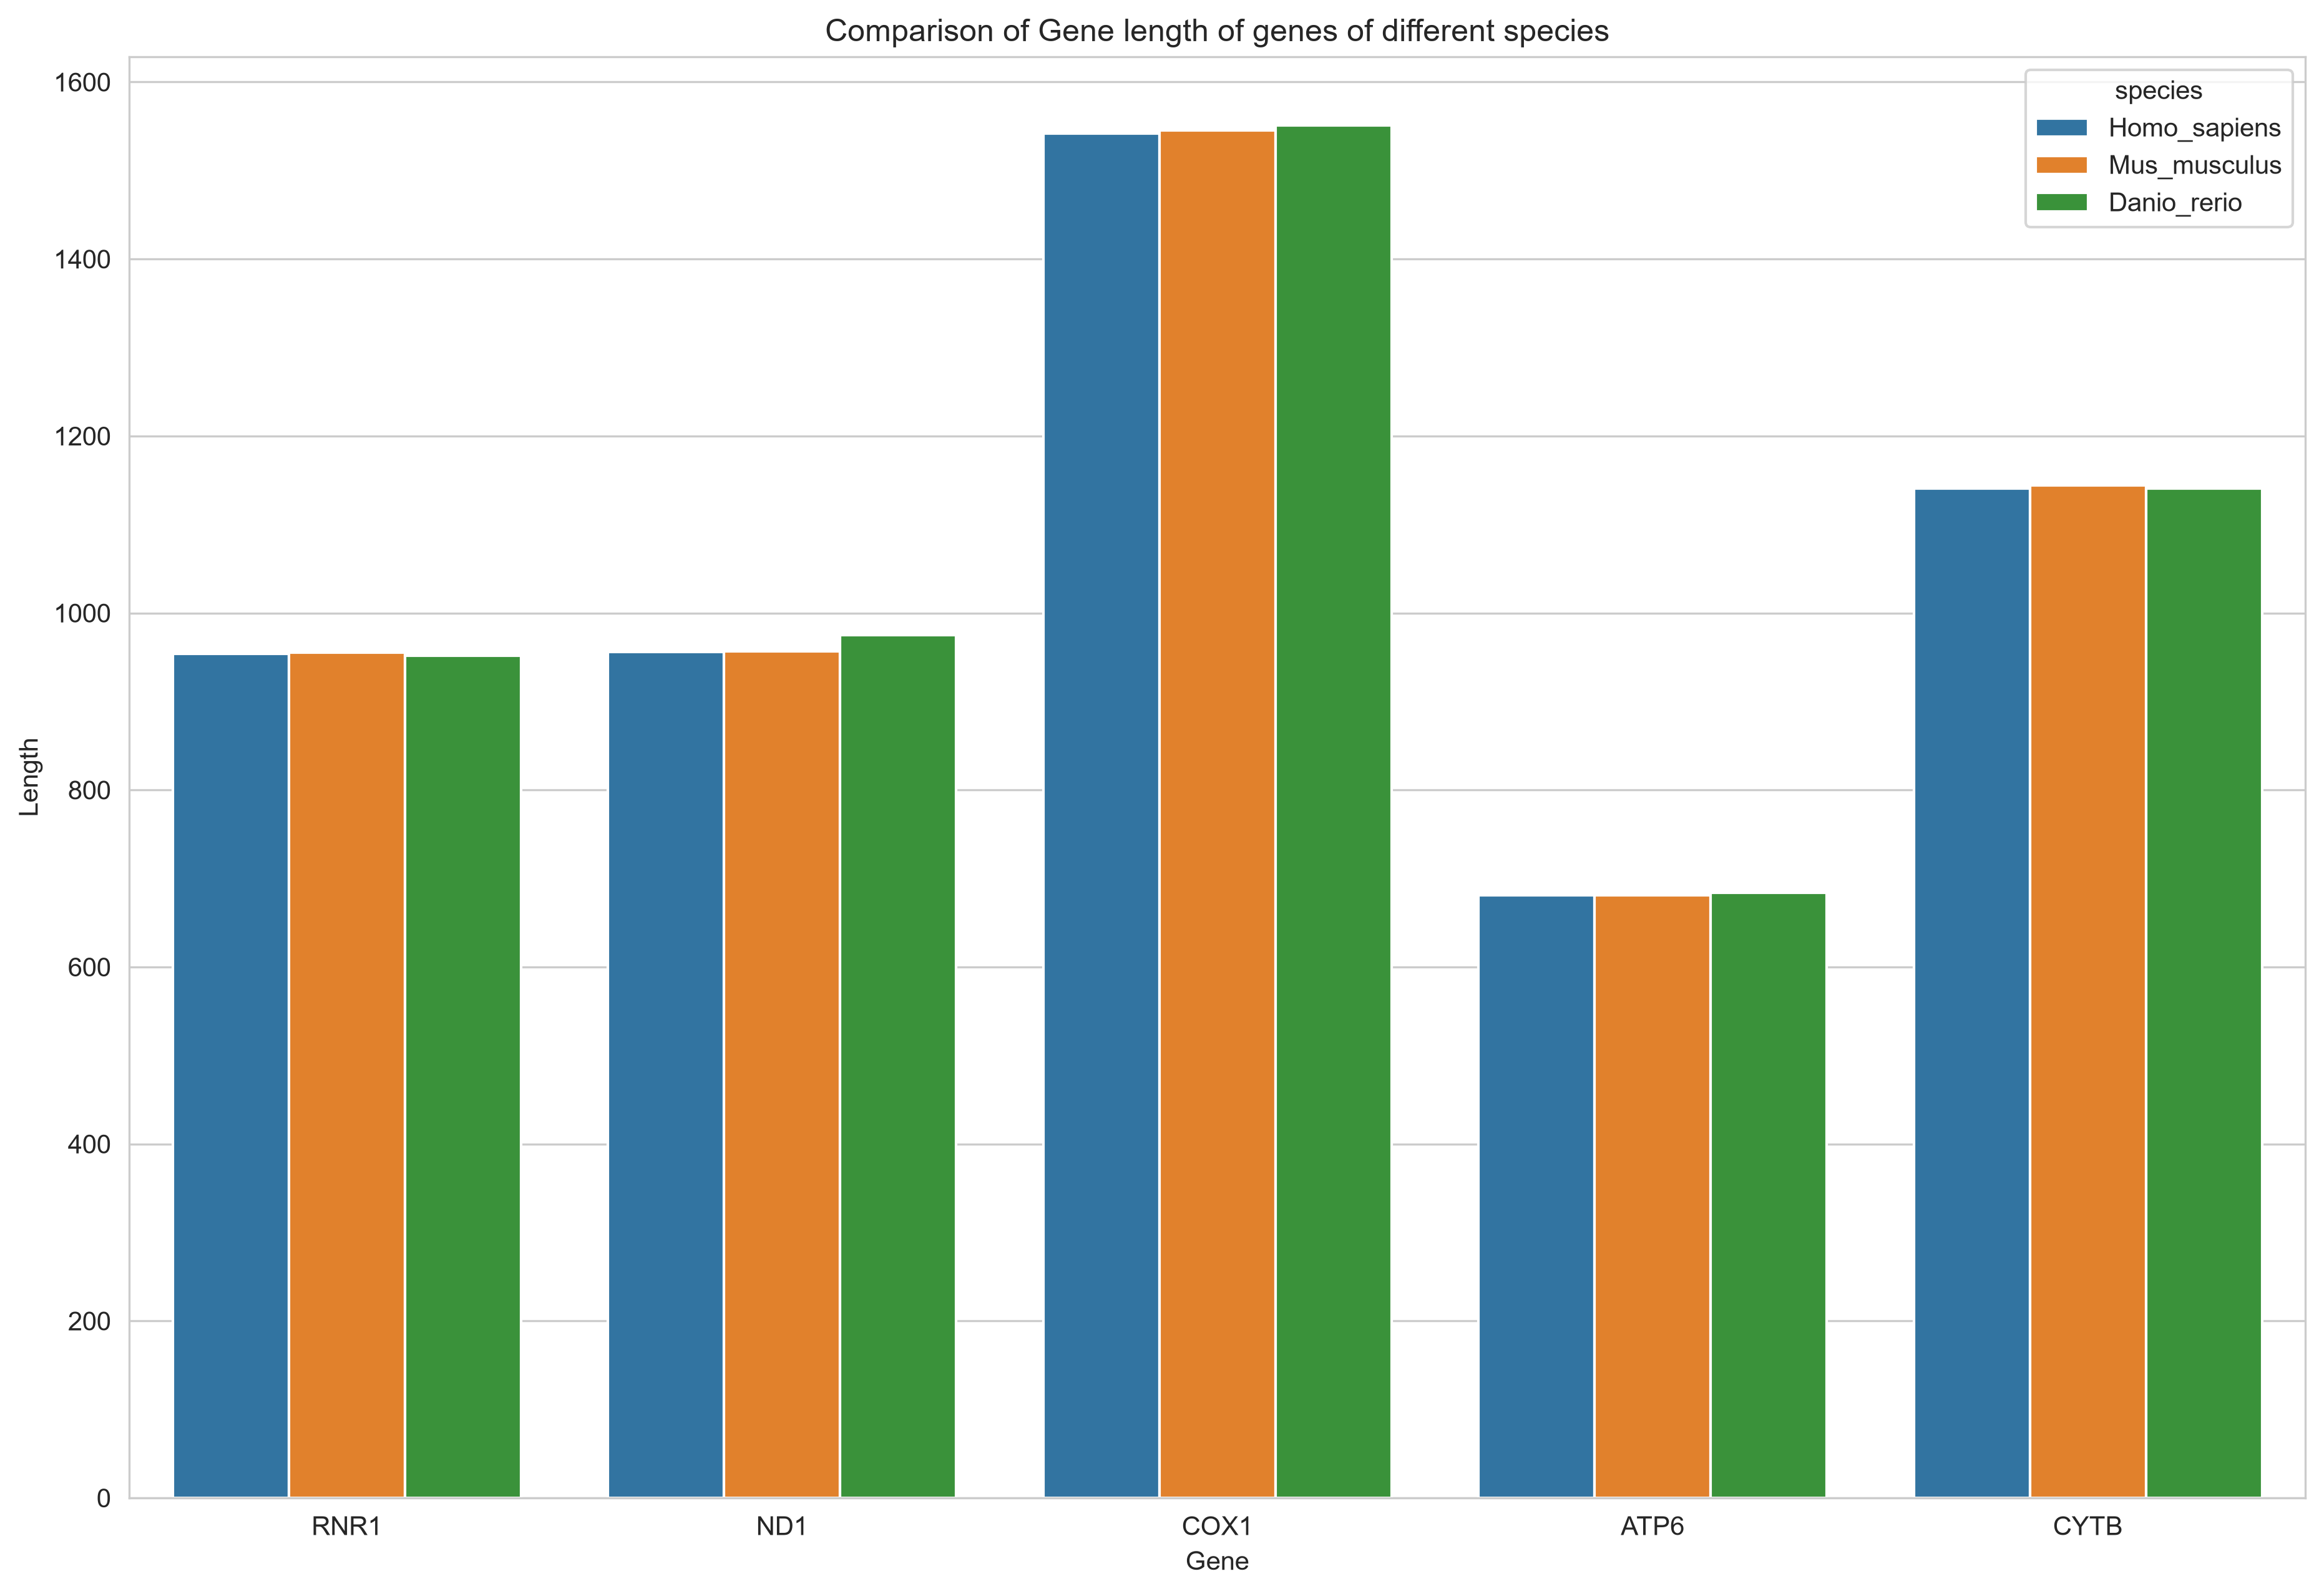

In [ ]:



plt.figure(figsize=(15,10),dpi=300)

sns.barplot(df,x='Gene',y='Length',hue='species')

plt.title("Comparison of Gene length of genes of different species")


plt.show()





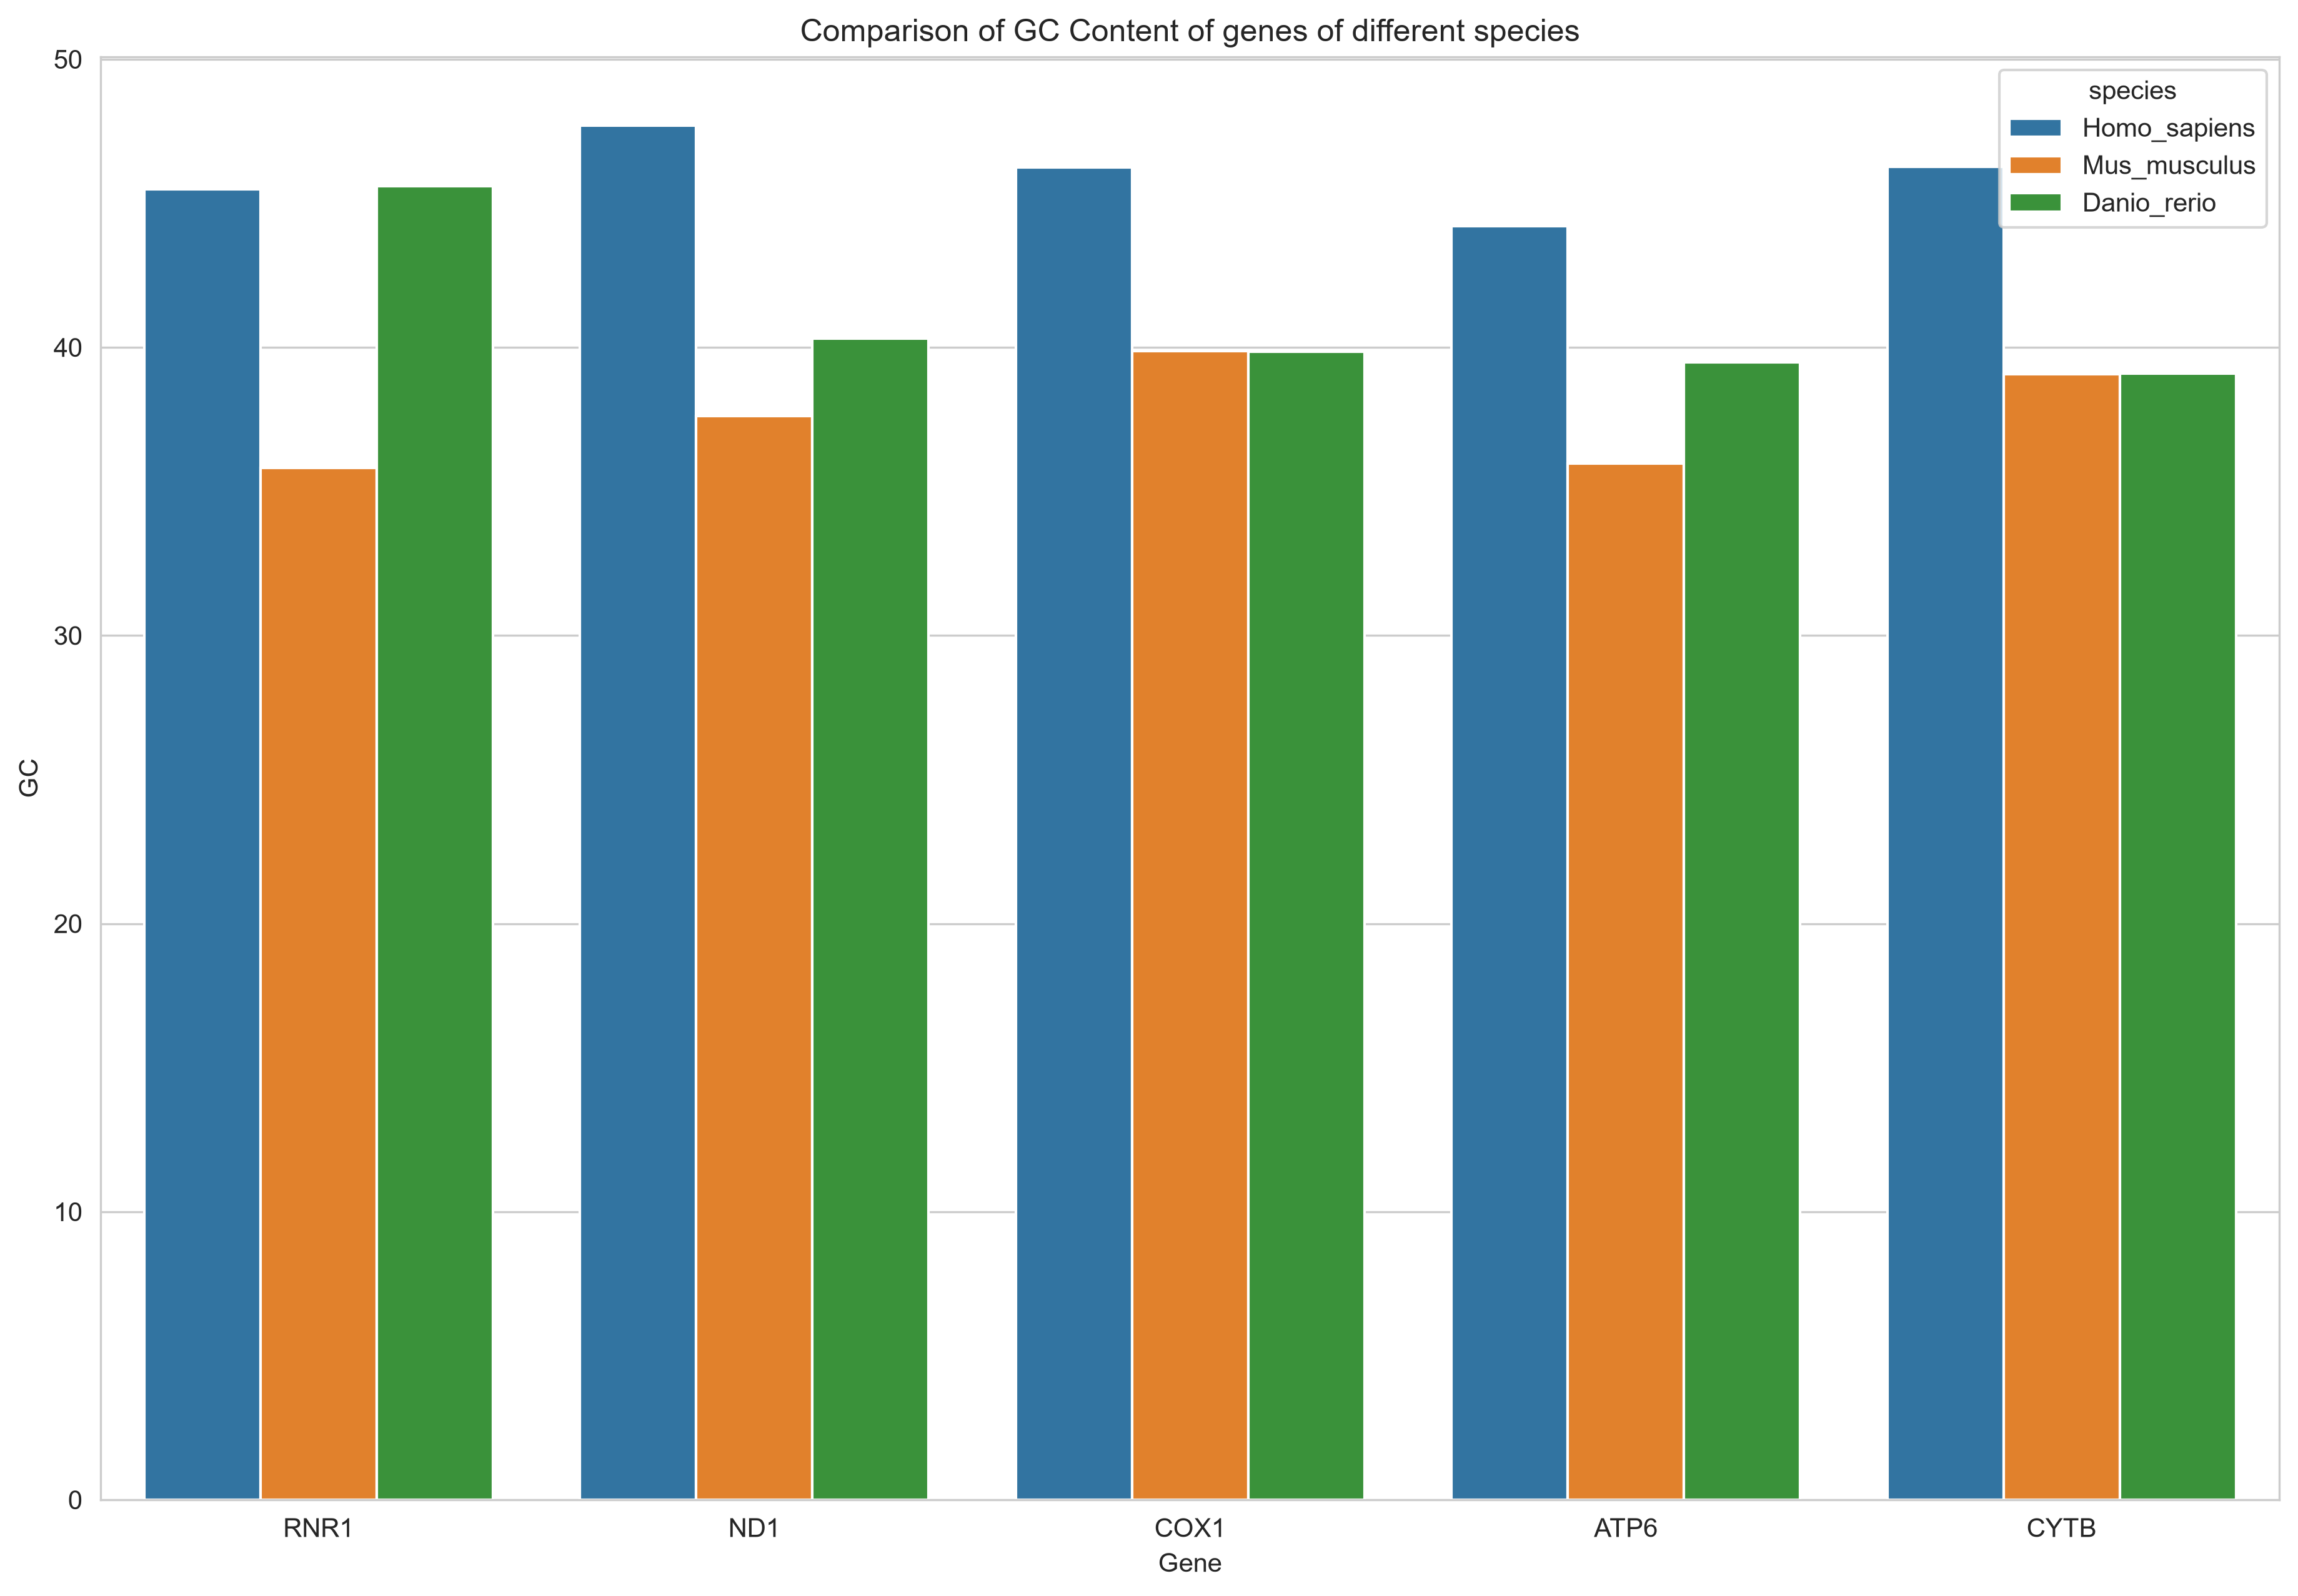

In [ ]:
plt.figure(figsize=(15,10),dpi=300)


sns.barplot(df,x='Gene',y='GC',hue='species')


plt.title("Comparison of GC Content of genes of different species")


plt.show()



In [ ]:
sns.set_style('darkgrid')
sns.pairplot(df,)

NameError: name 'sns' is not defined

<Figure size 1500x1000 with 0 Axes>

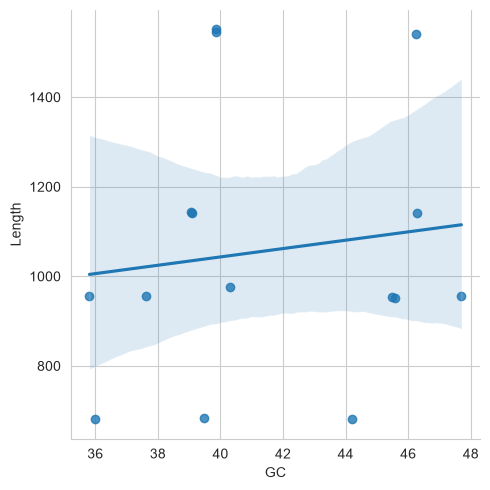

In [ ]:
plt.figure(figsize=(15,10))
sns.set_style('whitegrid')
sns.lmplot(data=df,x='GC',y='Length')

plt.show()


<Axes: xlabel='species', ylabel='GC'>

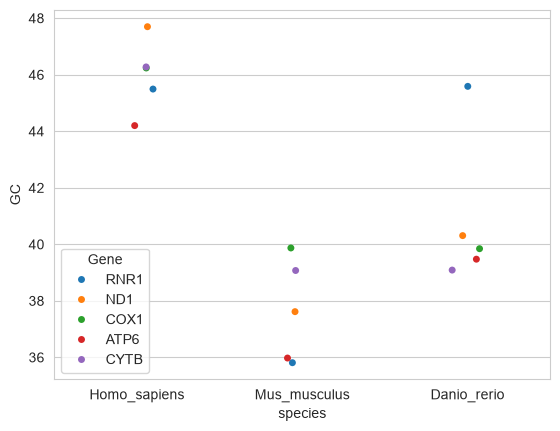

In [ ]:
sns.stripplot(data=df,x='species',y='GC',hue='Gene',legend='full')

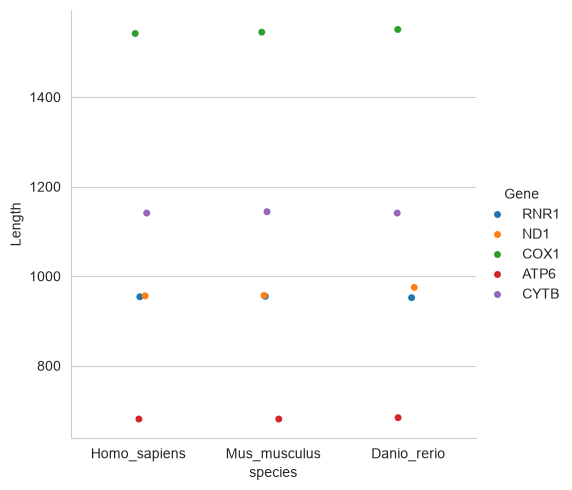

In [ ]:
sns.catplot(data=df,x='species',y='Length',hue='Gene')

<Axes: xlabel='species', ylabel='GC'>

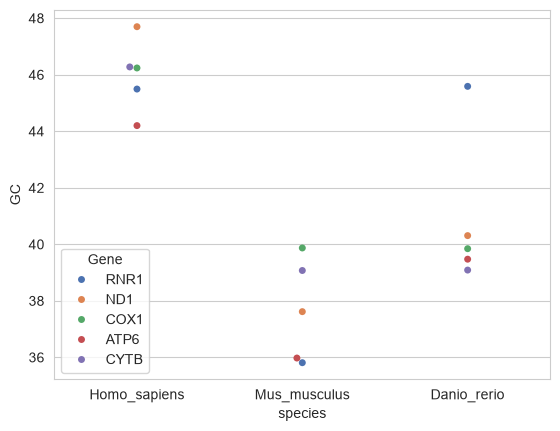

In [ ]:
sns.swarmplot(data=df,x='species',y='GC',hue='Gene',palette='deep')

In [ ]:
pivot=df.pivot_table(index='Gene',values=['GC','Length'],columns='species',aggfunc=['mean'])
pivot

mean                                                     \
                 GC                                Length                
species Danio_rerio Homo_sapiens Mus_musculus Danio_rerio Homo_sapiens   
Gene                                                                     
ATP6      39.473684    44.199706    35.976505       684.0        681.0   
COX1      39.845261    46.238651    39.870550      1551.0       1542.0   
CYTB      39.088519    46.275197    39.073427      1141.0       1141.0   
ND1       40.307692    47.698745    37.617555       975.0        956.0   
RNR1      45.588235    45.492662    35.811518       952.0        954.0   

                      
                      
species Mus_musculus  
Gene                  
ATP6           681.0  
COX1          1545.0  
CYTB          1144.0  
ND1            957.0  
RNR1           955.0

<Axes: xlabel='None-None-species', ylabel='Gene'>

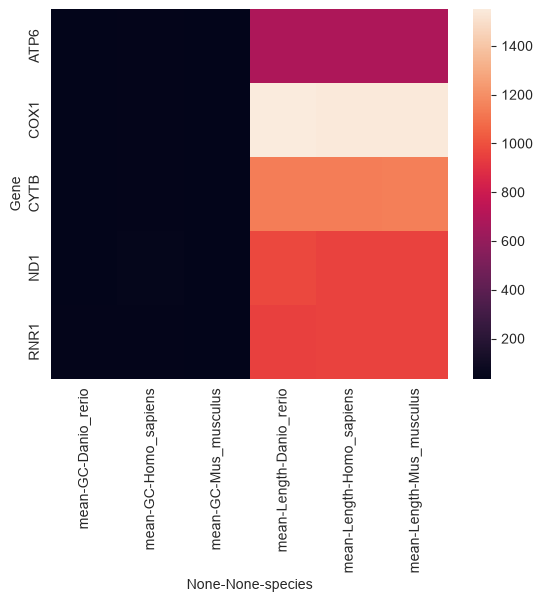

In [ ]:
sns.heatmap(pivot)

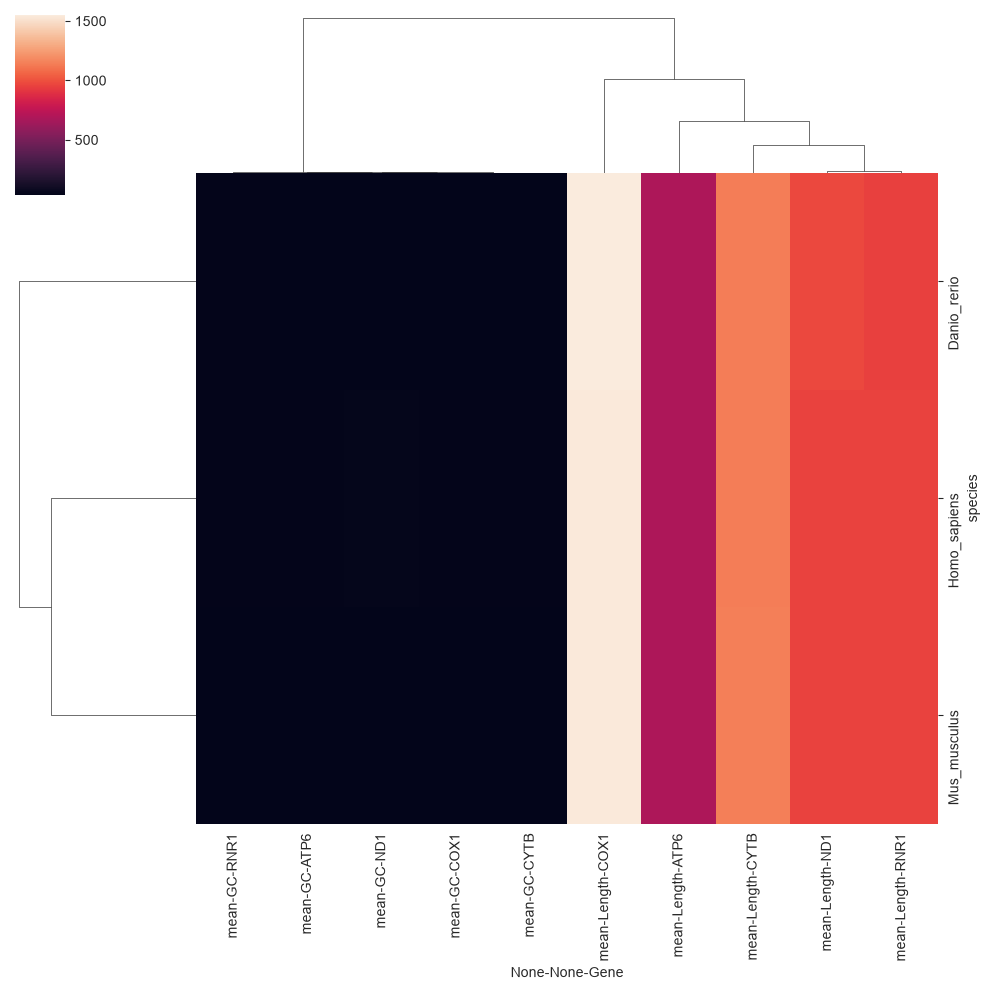

In [ ]:
sns.clustermap(df.pivot_table(index='species',columns='Gene',values=['GC','Length'],aggfunc=['mean']))

<Axes: xlabel='species', ylabel='Length'>

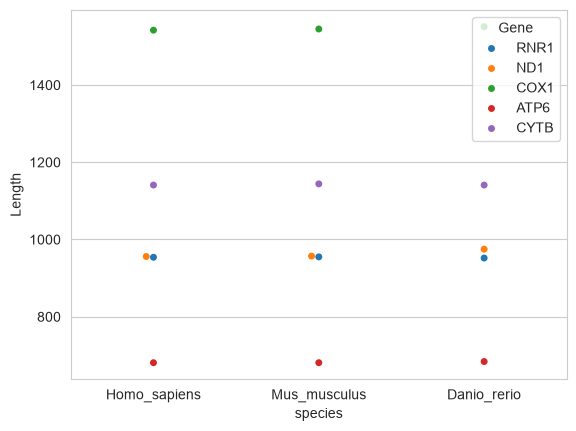

In [ ]:
sns.swarmplot(df,x="species",y='Length',hue='Gene')

<h1>Milestone 2</h1>

In [ ]:

species={
    'Homo_sapiens':"NC_012920",
    'Mus_musculus':'NC_005089',
    'Danio_rerio':'NC_002333'
}
#print(species)
from collections import Counter

Entrez.email=''
Dataset=[]
for species,accessions in species.items():
    handle=Entrez.efetch(db='nucleotide',id=accessions,rettype='gb',retmode='text')
    record=SeqIO.read(handle,'genbank')
    handle.close()
    for rec in record.features:
        record_gene=rec.qualifiers.get("gene",[])
        recordFeature=rec.extract(record.seq)
        count_from_DNA=Counter(recordFeature)
        
        Dataset.append({
            'species':species,
            'Gene': str(record_gene),
            'DNA': str(recordFeature),
            'GC':GC123(record.seq)[0],
            "Length":len(recordFeature),
            "A":count_from_DNA['A'],
            'T':count_from_DNA['T'],
            'G':count_from_DNA['G'],
            'C':count_from_DNA['C'],
            'RNA':recordFeature.transcribe(),
            'protien':recordFeature.translate(),
            
        })

df=pd.DataFrame(Dataset)
#df

C:\Users\saini\AppData\Roaming\Python\Python311\site-packages\Bio\Seq.py:2874: BiopythonWarning: Partial codon, len(sequence) not a multiple of three. Explicitly trim the sequence or add trailing N before translation. This may become an error in future.
  warnings.warn(


In [ ]:
for i in range(len(df)):
    if df.loc[i,'Gene']=='[]':
        df=df.drop(i,axis=0)
df


,species,Gene,DNA,GC,Length,A,T,G,C,RNA,protien
2,Homo_sapiens,['TRNF'],GTTTATGTAGCTTACCTCCTCAAAGCAATACACTGAAAATGTTTAG...,44.362627,71,24,18,10,19,"(G, U, U, U, A, U, G, U, A, G, C, U, U, A, C, ...","(V, Y, V, A, Y, L, L, K, A, I, H, *, K, C, L, ..."
3,Homo_sapiens,['RNR1'],AATAGGTTTGGTCCTAGCCTTTCTATTAGCTCTTAGTAAGATTACA...,44.362627,954,315,205,181,253,"(A, A, U, A, G, G, U, U, U, G, G, U, C, C, U, ...","(N, R, F, G, P, S, L, S, I, S, S, *, *, D, Y, ..."
4,Homo_sapiens,['TRNV'],CAGAGTGTAGCTTAACACAAAGCACCCAACTTACACTTAGGAGATT...,44.362627,69,23,17,11,18,"(C, A, G, A, G, U, G, U, A, G, C, U, U, A, A, ...","(Q, S, V, A, *, H, K, A, P, N, L, H, L, G, D, ..."
5,Homo_sapiens,['RNR2'],GCTAAACCTAGCCCCAAACCCACTCCACCTTACTACCAGACAACCT...,44.362627,1559,547,344,270,397,"(G, C, U, A, A, A, C, C, U, A, G, C, C, C, C, ...","(A, K, P, S, P, K, P, T, P, P, Y, Y, Q, T, T, ..."
7,Homo_sapiens,['TRNL1'],GTTAAGATGGCAGAGCCCGGTAATCGCATAAAACTTAAAACTTTAC...,44.362627,75,25,21,13,16,"(G, U, U, A, A, G, A, U, G, G, C, A, G, A, G, ...","(V, K, M, A, E, P, G, N, R, I, K, L, K, T, L, ..."
...,...,...,...,...,...,...,...,...,...,...,...
127,Danio_rerio,['ND6'],ATGGCATTTTATTTGTCTTTTTTGATGGCAGCTCTAGTTGGGGGTA...,39.931309,519,89,221,145,64,"(A, U, G, G, C, A, U, U, U, U, A, U, U, U, G, ...","(M, A, F, Y, L, S, F, L, M, A, A, L, V, G, G, ..."
128,Danio_rerio,['trnE'],GTTCTTGTAGTTGAACTACAACAGTGGTTTTTCGAGTCACCGGTCT...,39.931309,69,18,24,16,11,"(G, U, U, C, U, U, G, U, A, G, U, U, G, A, A, ...","(V, L, V, V, E, L, Q, Q, W, F, F, E, S, P, V, ..."
129,Danio_rerio,['CYTB'],ATGACAAGCCTGCGAAAAACACACCCAGTTTTAAAAATCGCTAATG...,39.931309,1141,330,365,169,277,"(A, U, G, A, C, A, A, G, C, C, U, G, C, G, A, ...","(M, T, S, L, R, K, T, H, P, V, L, K, I, A, N, ..."
130,Danio_rerio,['trnT'],GCCCTAGTAGCTTAGTTTTAAAGCATCGGTCTTGTAATCCGAAGAT...,39.931309,72,16,20,17,19,"(G, C, C, C, U, A, G, U, A, G, C, U, U, A, G, ...","(A, L, V, A, *, F, *, S, I, G, L, V, I, R, R, ..."


In [ ]:
df=df.drop_duplicates(ignore_index=True)
df.to_csv('MileStone2.csv')
df

,species,Gene,DNA,GC,Length,A,T,G,C,RNA,protien
0,Homo_sapiens,['TRNF'],GTTTATGTAGCTTACCTCCTCAAAGCAATACACTGAAAATGTTTAG...,44.362627,71,24,18,10,19,"(G, U, U, U, A, U, G, U, A, G, C, U, U, A, C, ...","(V, Y, V, A, Y, L, L, K, A, I, H, *, K, C, L, ..."
1,Homo_sapiens,['RNR1'],AATAGGTTTGGTCCTAGCCTTTCTATTAGCTCTTAGTAAGATTACA...,44.362627,954,315,205,181,253,"(A, A, U, A, G, G, U, U, U, G, G, U, C, C, U, ...","(N, R, F, G, P, S, L, S, I, S, S, *, *, D, Y, ..."
2,Homo_sapiens,['TRNV'],CAGAGTGTAGCTTAACACAAAGCACCCAACTTACACTTAGGAGATT...,44.362627,69,23,17,11,18,"(C, A, G, A, G, U, G, U, A, G, C, U, U, A, A, ...","(Q, S, V, A, *, H, K, A, P, N, L, H, L, G, D, ..."
3,Homo_sapiens,['RNR2'],GCTAAACCTAGCCCCAAACCCACTCCACCTTACTACCAGACAACCT...,44.362627,1559,547,344,270,397,"(G, C, U, A, A, A, C, C, U, A, G, C, C, C, C, ...","(A, K, P, S, P, K, P, T, P, P, Y, Y, Q, T, T, ..."
4,Homo_sapiens,['TRNL1'],GTTAAGATGGCAGAGCCCGGTAATCGCATAAAACTTAAAACTTTAC...,44.362627,75,25,21,13,16,"(G, U, U, A, A, G, A, U, G, G, C, A, G, A, G, ...","(V, K, M, A, E, P, G, N, R, I, K, L, K, T, L, ..."
...,...,...,...,...,...,...,...,...,...,...,...
113,Danio_rerio,['ND6'],ATGGCATTTTATTTGTCTTTTTTGATGGCAGCTCTAGTTGGGGGTA...,39.931309,519,89,221,145,64,"(A, U, G, G, C, A, U, U, U, U, A, U, U, U, G, ...","(M, A, F, Y, L, S, F, L, M, A, A, L, V, G, G, ..."
114,Danio_rerio,['trnE'],GTTCTTGTAGTTGAACTACAACAGTGGTTTTTCGAGTCACCGGTCT...,39.931309,69,18,24,16,11,"(G, U, U, C, U, U, G, U, A, G, U, U, G, A, A, ...","(V, L, V, V, E, L, Q, Q, W, F, F, E, S, P, V, ..."
115,Danio_rerio,['CYTB'],ATGACAAGCCTGCGAAAAACACACCCAGTTTTAAAAATCGCTAATG...,39.931309,1141,330,365,169,277,"(A, U, G, A, C, A, A, G, C, C, U, G, C, G, A, ...","(M, T, S, L, R, K, T, H, P, V, L, K, I, A, N, ..."
116,Danio_rerio,['trnT'],GCCCTAGTAGCTTAGTTTTAAAGCATCGGTCTTGTAATCCGAAGAT...,39.931309,72,16,20,17,19,"(G, C, C, C, U, A, G, U, A, G, C, U, U, A, G, ...","(A, L, V, A, *, F, *, S, I, G, L, V, I, R, R, ..."


In [ ]:

from collections import Counter
Count_gene=Counter(df['Gene'])
Count_species=Counter(df['species'])
Count_gene,Count_species

(Counter({"['ND4']": 5,
          "['COX3']": 4,
          "['ND3']": 4,
          "['ND5']": 4,
          "['ND1']": 3,
          "['ND2']": 3,
          "['COX1']": 3,
          "['COX2']": 3,
          "['ATP8']": 3,
          "['ATP6']": 3,
          "['ND4L']": 3,
          "['ND6']": 3,
          "['CYTB']": 3,
          "['mt-Rnr2']": 2,
          "['TrnR']": 2,
          "['TRNF']": 1,
          "['RNR1']": 1,
          "['TRNV']": 1,
          "['RNR2']": 1,
          "['TRNL1']": 1,
          "['TRNI']": 1,
          "['TRNQ']": 1,
          "['TRNM']": 1,
          "['TRNW']": 1,
          "['TRNA']": 1,
          "['TRNN']": 1,
          "['TRNC']": 1,
          "['TRNY']": 1,
          "['TRNS1']": 1,
          "['TRND']": 1,
          "['TRNK']": 1,
          "['TRNG']": 1,
          "['TRNR']": 1,
          "['TRNH']": 1,
          "['TRNS2']": 1,
          "['TRNL2']": 1,
          "['TRNE']": 1,
          "['TRNT']": 1,
          "['TRNP']": 1,
          "['TrnF']": 1,

In [ ]:
from sklearn.preprocessing import StandardScaler



from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(df[['Length','A','G','T','C','GC']],df[['species']])

In [ ]:
X_train.shape,X_test.shape,Y_train.shape,Y_test.shape

((88, 6), (30, 6), (88, 1), (30, 1))

In [ ]:
scaler=StandardScaler()
model=scaler.fit(X_train)
X_train_scaled=model.transform(X_train)
X_test_scaled=model.transform(X_test)

In [ ]:
X_train_scaled=pd.DataFrame(X_train_scaled,columns=X_train.columns)
X_train_scaled

,Length,A,G,T,C,GC
0,-0.642574,-0.636232,-0.585835,-0.663170,-0.606535,-0.617948
1,0.975120,1.273096,1.094860,0.874321,0.568919,0.780303
2,-0.760853,-0.736430,-0.780699,-0.774868,-0.701112,-0.752395
3,-0.640754,-0.602832,-0.634551,-0.650029,-0.626801,-0.649319
4,-0.760853,-0.730863,-0.780699,-0.781438,-0.701112,-0.752395
...,...,...,...,...,...,...
83,-0.760853,-0.736430,-0.768520,-0.781438,-0.701112,-0.747914
84,-0.640754,-0.580566,-0.683267,-0.663170,-0.613290,-0.658282
85,-0.637115,-0.613966,-0.610193,-0.623747,-0.640312,-0.649319
86,-0.222228,-0.241006,-0.378793,-0.216378,-0.099874,-0.205643


In [ ]:
X_test_scaled=pd.DataFrame(X_test_scaled,columns=X_train.columns)
X_test_scaled

,Length,A,G,T,C,GC
0,-0.637115,-0.613966,-0.573656,-0.702592,-0.579513,-0.595540
1,-0.629836,-0.597266,-0.610193,-0.650029,-0.606535,-0.626911
2,-0.638935,-0.575000,-0.646730,-0.663170,-0.633557,-0.658282
3,-0.642574,-0.625099,-0.561477,-0.663170,-0.633557,-0.626911
4,-0.638935,-0.586133,-0.695446,-0.630317,-0.626801,-0.671727
5,-0.637115,-0.608399,-0.646730,-0.669740,-0.579513,-0.622430
6,-0.638935,-0.586133,-0.671088,-0.650029,-0.620046,-0.658282
7,-0.222228,-0.268839,-0.342256,-0.222948,-0.079607,-0.178754
8,0.978760,0.983635,0.571165,1.110857,0.981004,0.860972
9,-0.631656,-0.647365,-0.573656,-0.650029,-0.572757,-0.591059


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score,accuracy_score,confusion_matrix,recall_score
from sklearn.preprocessing import LabelEncoder

#KNN
model=KNeighborsClassifier(5)

label=LabelEncoder()
label.fit(Y_train)
Y_train=label.transform(Y_train)
Y_test=label.transform(Y_test)

model.fit(X_train_scaled,Y_train)



c:\ProgramData\anaconda3\Lib\site-packages\sklearn\preprocessing\_label.py:103: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\preprocessing\_label.py:139: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\preprocessing\_label.py:139: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [ ]:
predicted=model.predict(X_test_scaled)
print(predicted,"\n\n",Y_test)
print(f1_score(Y_test,predicted,average='macro'),accuracy_score(Y_test,y_pred=predicted),'\n',confusion_matrix(Y_test,predicted),"\n",recall_score(Y_test,predicted,average='macro'))


[0 0 1 0 1 1 1 0 0 0 0 1 2 2 0 0 0 2 2 1 0 0 1 0 0 0 0 0 0 0] 

 [0 0 2 1 1 1 2 1 2 0 0 0 1 2 1 0 2 2 2 2 1 1 1 0 0 2 2 1 1 0]
0.4444444444444444 0.4666666666666667 
 [[8 1 0]
 [7 3 1]
 [4 3 3]] 
 0.4872053872053872


In [ ]:
print(f1_score(predicted,Y_test,average='macro'))


0.4444444444444444


In [ ]:
from sklearn.tree import DecisionTreeClassifier


#DecisionTree
tree=DecisionTreeClassifier()

tree.fit(X_train,Y_train)


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [ ]:
predicted=tree.predict(X_test)
print(predicted,'\n\n',Y_test)

[0 1 1 1 1 0 1 2 0 0 1 1 0 2 1 2 0 2 2 1 1 0 2 2 2 2 1 2 1 0] 

 [0 0 2 1 1 1 2 1 2 0 0 0 1 2 1 0 2 2 2 2 1 1 1 0 0 2 2 1 1 0]


In [ ]:

print(f1_score(predicted,Y_test,average='macro'),"\n",confusion_matrix(Y_test,predicted),recall_score(Y_test,predicted,average='macro'))


0.39590792838874683 
 [[3 3 3]
 [3 5 3]
 [2 4 4]] 0.395959595959596


In [ ]:
# RandomForest
from sklearn.ensemble import RandomForestClassifier
Rnd=RandomForestClassifier()
Rnd.fit(X_train,Y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [ ]:
predicted=Rnd.predict(X_test)
print(f1_score(Y_test,predicted,average='macro'))

0.6295448766844647


<h1>Prashant</h1>